# 07 · E6 + E8: bad weather (RQ4)

**Question (RQ4).** How much does accuracy drop under simulated fog, rain and low light, and can training
augmentation reduce the drop?

* **E6** trains FINAL's recipe with half of the training images weather-augmented (Albumentations fog, rain,
  darkening + noise). Validation and test stay clean.
* **E8** scores FINAL and E6 on the test set corrupted by **our own** fog / rain / low-light code at three severities
  (a different implementation from the training augmentation, so E6 cannot just learn the generator).

**Setup.** Installs the pinned library versions on Kaggle and imports the shared code (`kitti_common.py`, written and
explained in `00_common.ipynb`): data access, the KITTI evaluator, training loops and plots.

In [1]:
SMOKE = False   # True = quick pipeline test (5 % of the data, 2 epochs); the numbers are then meaningless

import os, sys, json, subprocess
from pathlib import Path
os.environ["KITTI_SMOKE"] = "1" if SMOKE else "0"
if Path("/kaggle/input").exists():                     # Kaggle: install the pinned libraries, find the shared code
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.214", "albumentations==2.0.8"],
                   check=True)
    for r, dirs, files in os.walk("/kaggle/input"):
        if "kitti_common.py" in files:
            sys.path.insert(0, r)
            break
        dirs[:] = [d for d in dirs if not d.startswith(("images", "labels", "label_2"))]
from kitti_common import *
seed_everything()
print("Kaggle" if ON_KAGGLE else "local", "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
      "| smoke test" if SMOKE else "")

Kaggle | GPU: Tesla T4 


## Settings and FINAL (from notebooks 04 and 05)

In [2]:
import_outputs("FINAL")
choice = json.loads((RESULTS / "final_config.json").read_text())
cfg = dict(choice["config"])
rfs, IMGSZ, batch = cfg.pop("rfs", False), cfg.pop("imgsz"), cfg.pop("batch")
choice["config"]

imported: ['FINAL'] | missing: []


{'imgsz': 960, 'batch': 16, 'rfs': True, 'lr0': 0.002}

## Data and the weather-augmented training set

In [3]:
tables = prepare_data()
images = tables[0]
weather_root, augmented = build_weather_train_set(split_ids(images, "train"))
print(f"{len(augmented)} of {len(split_ids(images, 'train'))} training images weather-augmented")
data_yaml = write_rfs_list(tables, root=weather_root)[0] if rfs else write_yaml(weather_root)

copy images/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy labels/train:   0%|          | 0/4699 [00:00<?, ?it/s]

copy images/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy labels/val:   0%|          | 0/1239 [00:00<?, ?it/s]

copy images/test:   0%|          | 0/1543 [00:00<?, ?it/s]

copy labels/test:   0%|          | 0/1543 [00:00<?, ?it/s]

data ready in /tmp/kitti: train 4699, val 1239, test 1543


weather-augmented train set:   0%|          | 0/4699 [00:00<?, ?it/s]

2349 of 4699 training images weather-augmented
RFS: 4699 training images -> 6157 per epoch


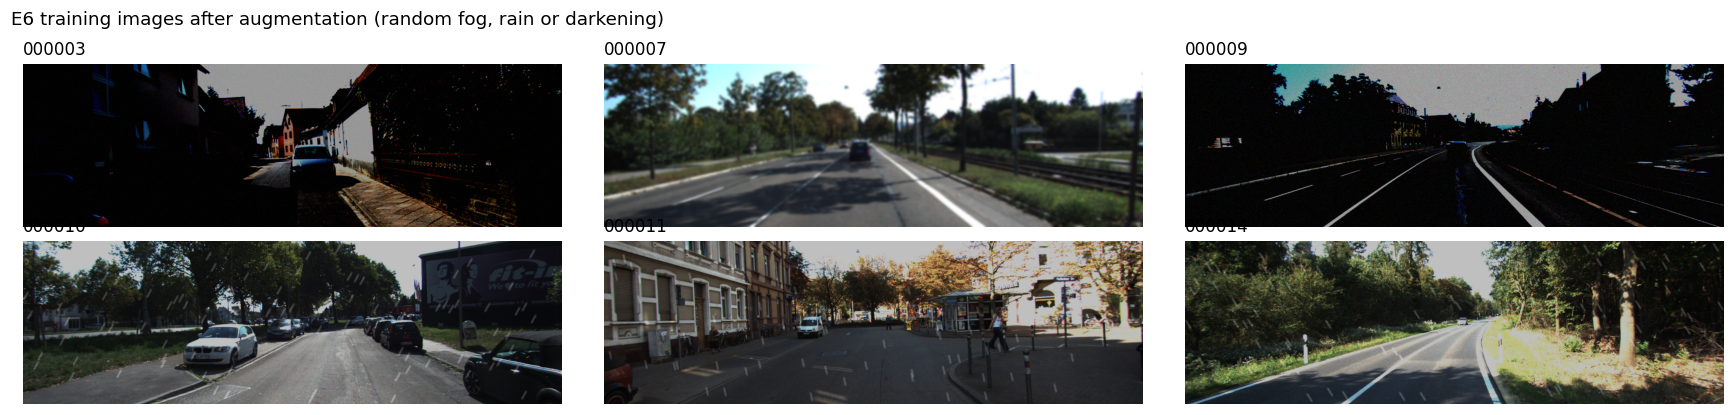

In [4]:
from PIL import Image
fig, ax = plt.subplots(2, 3, figsize=(16, 3.8))
for a, iid in zip(ax.flat, augmented[:6]):
    a.imshow(Image.open(weather_root / "images" / "train" / f"{iid}.png")); a.set_title(iid, loc="left"); a.axis("off"); a.grid(False)
fig.suptitle("E6 training images after augmentation (random fog, rain or darkening)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## E6 training

In [5]:
w, info = yolo_train("E6", choice["base"], data_yaml, imgsz=IMGSZ, epochs=50, batch=batch, **cfg)
info["settings"] = json.dumps({**choice["config"], "weather_fraction": 0.5})
info

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
training E6: yolov8s.pt, up to 50 epochs, imgsz 960, batch 16, changes: {'lr0': 0.002}
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/kitti_weather/train_rfs.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      7.37G       1.23      1.023      1.114        150        960: 100% ━━━━━━━━━━━━ 385/385 2.4it/s 2:39
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 5.3it/s 7.4s
                   all       1239       7296      0.488      0.579       0.49      0.308

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50       7.7G      1.144     0.8828       1.07        144        960: 100% ━━━━━━━━━━━━ 385/385 2.4it/s 2:39
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 5.3it/s 7.3s
                   all       1239       7296      0.679      0.496      0.523      0.329

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      7.53G      1.096     0.8108      1.047        160        960: 100% ━━━━━━━━━━━━ 385/385 2.4it/s 2:39
                 Class     Images  Instances      Box(P 

{'model': 'yolov8s.pt',
 'imgsz': 960,
 'batch': 16,
 'max_epochs': 50,
 'epochs_run': 13,
 'best_epoch': 3,
 'train_hours': 0.639,
 'settings': '{"imgsz": 960, "batch": 16, "rfs": true, "lr0": 0.002, "weather_fraction": 0.5}',
 'data': 'train_rfs.yaml',
 'ultralytics_val_mAP50': 0.52315,
 'ultralytics_val_mAP50_95': 0.32897}

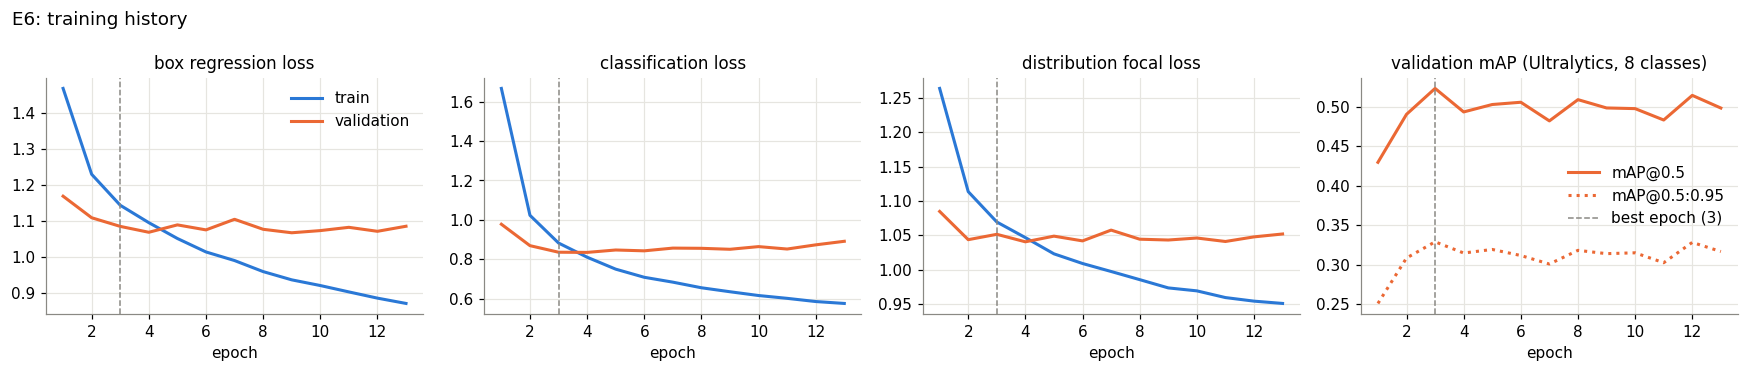

In [6]:
plot_yolo_history("E6")

## Validation (clean)

In [7]:
val, val_table, _ = evaluate_model("E6", "yolo", w, tables, "val", imgsz=IMGSZ)
headline(**{"E6 val": val, "FINAL val": {k[4:]: v for k, v in load_record("FINAL").items() if k.startswith("val_")}})

E6 on val:   0%|          | 0/78 [00:00<?, ?it/s]

,E6 val,FINAL val
"Primary (Car/Ped/Cyc, Moderate)",0.748,0.758
Car,0.967,0.969
Pedestrian,0.751,0.762
Cyclist,0.527,0.545
Easy (3 classes),0.854,0.878
Hard (3 classes),0.697,0.708
Car AP@0.7,0.937,0.935
"mAP@0.5, all 8 classes",0.510,0.510
"mAP@0.5:0.95, all 8 classes",0.310,0.315


## Test set (once)

The model is now fixed: every choice above was made on validation. It is scored once on the test set, i.e. on drives
it has never seen.

In [8]:
test, test_table, test_preds = evaluate_model("E6", "yolo", WEIGHTS / "E6.pt", tables, "test", imgsz=IMGSZ)
headline(validation=val, test=test)

E6 on test:   0%|          | 0/97 [00:00<?, ?it/s]

,validation,test
"Primary (Car/Ped/Cyc, Moderate)",0.748,0.804
Car,0.967,0.968
Pedestrian,0.751,0.834
Cyclist,0.527,0.611
Easy (3 classes),0.854,0.833
Hard (3 classes),0.697,0.782
Car AP@0.7,0.937,0.937
"mAP@0.5, all 8 classes",0.510,0.508
"mAP@0.5:0.95, all 8 classes",0.310,0.312


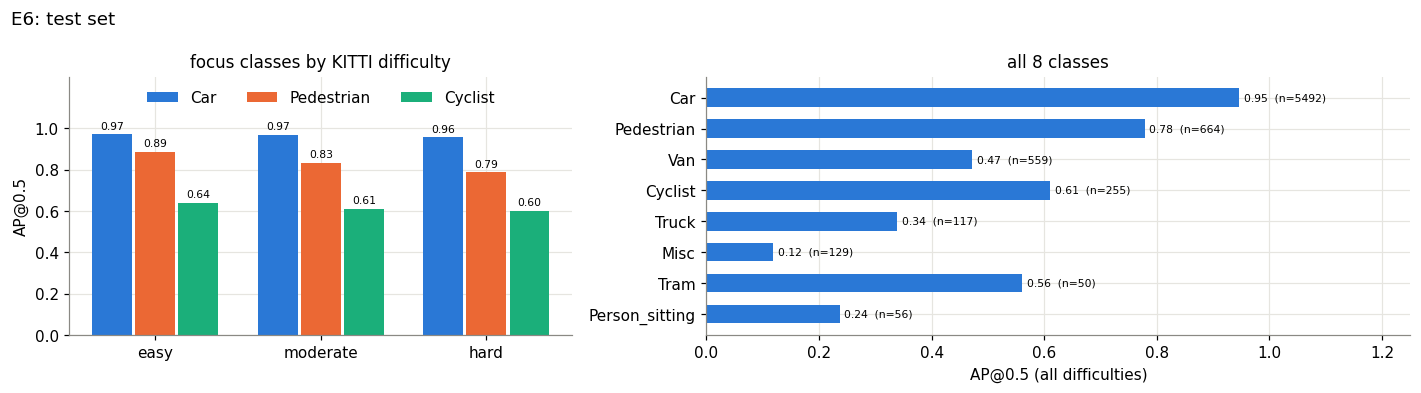

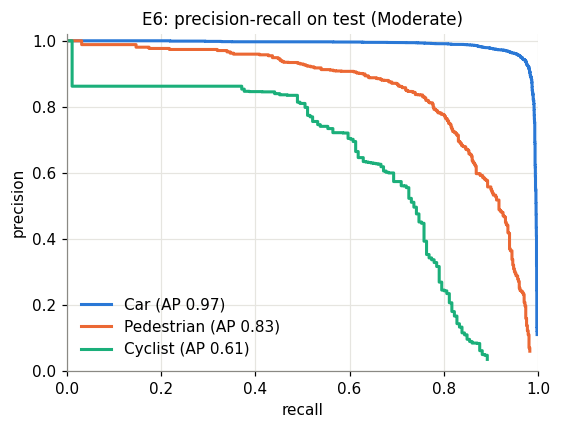

In [9]:
plot_per_class("E6", test_table, "test set")
plot_pr("E6", test_preds, tables, "test")

Ultralytics' own test evaluation, as a cross-check, with its normalised confusion matrix (rows: predicted class, columns: true class; *background* = missed objects / false alarms).

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 11,128,680 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5030.1±744.5 MB/s, size: 780.8 KB)
val: Scanning /tmp/kitti/labels/test... 1543 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1543/1543 173.8it/s 8.9s
val: New cache created: /tmp/kitti/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 5.1it/s 19.1s
                   all       1543       7322      0.567      0.465      0.494      0.317
Speed: 0.7ms preprocess, 7.4ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /tmp/runs/E6_test


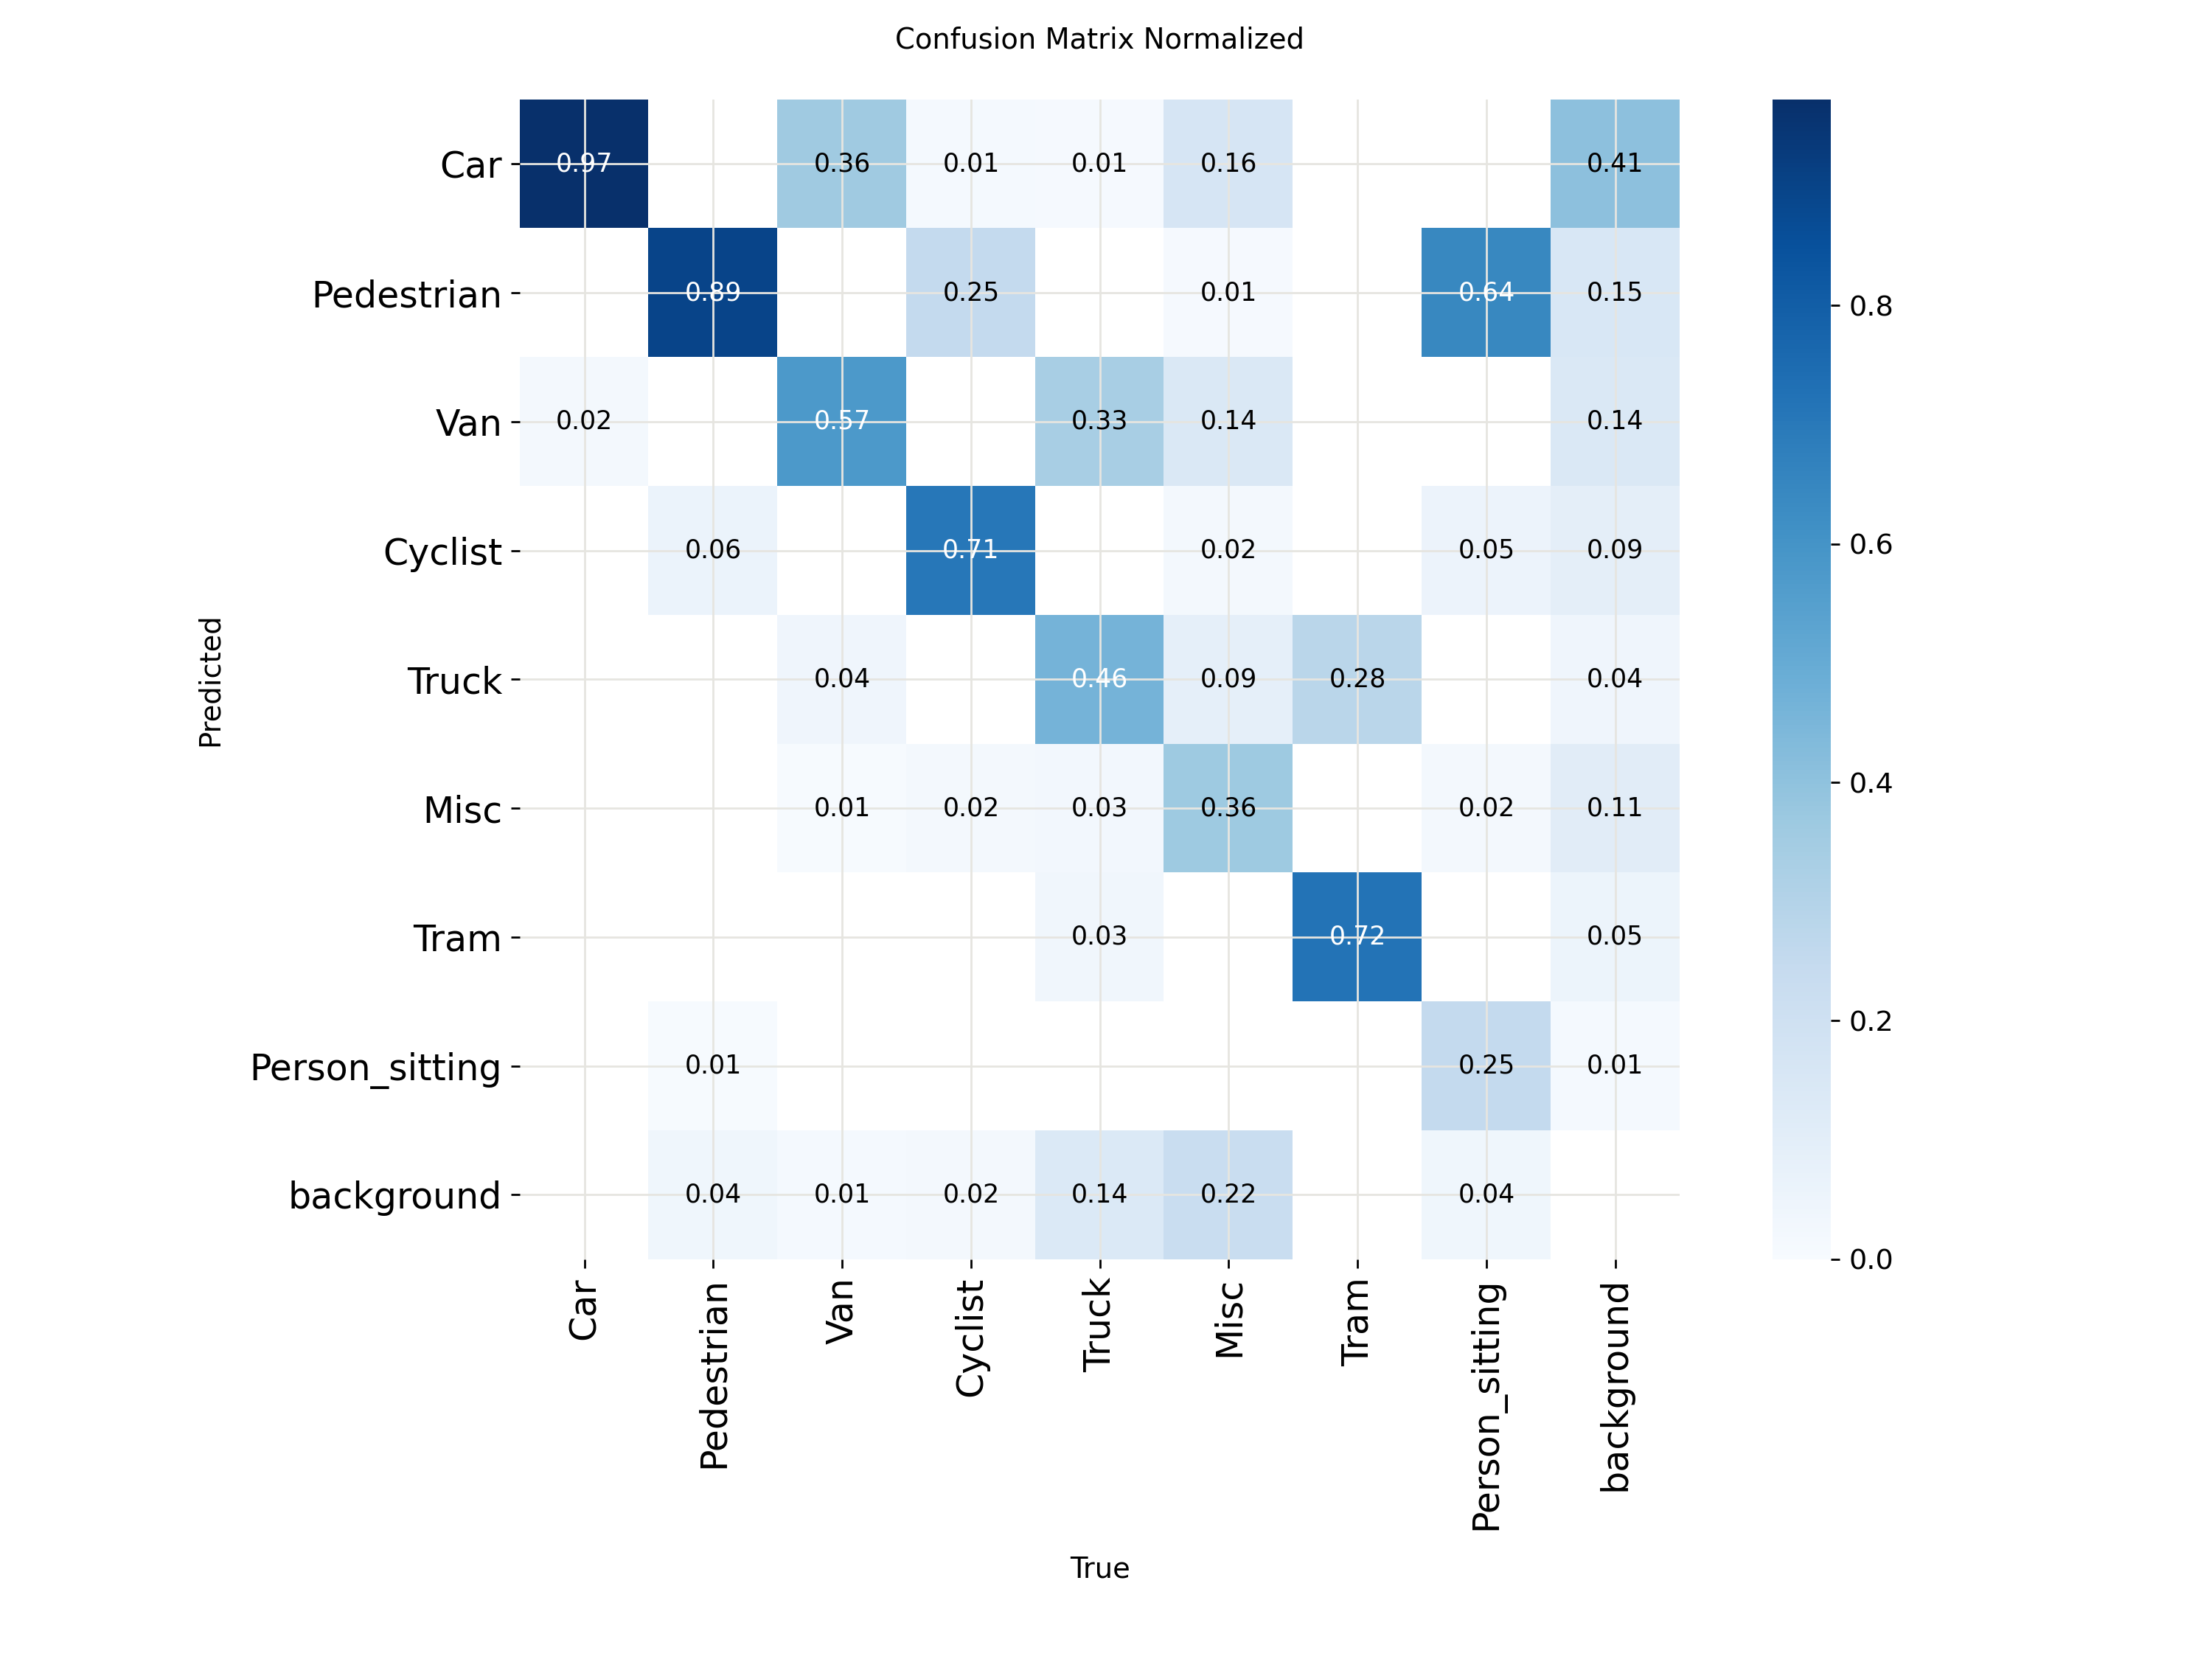

{'ultralytics_mAP50': 0.4936624371301549,
 'ultralytics_mAP50_95': 0.31687650877506}

In [10]:
ultra = ultralytics_test_report("E6", WEIGHTS / "E6.pt", IMGSZ)
ultra

A few test images (the same ones in every notebook): detections with score ≥ 0.4 against the ground truth.

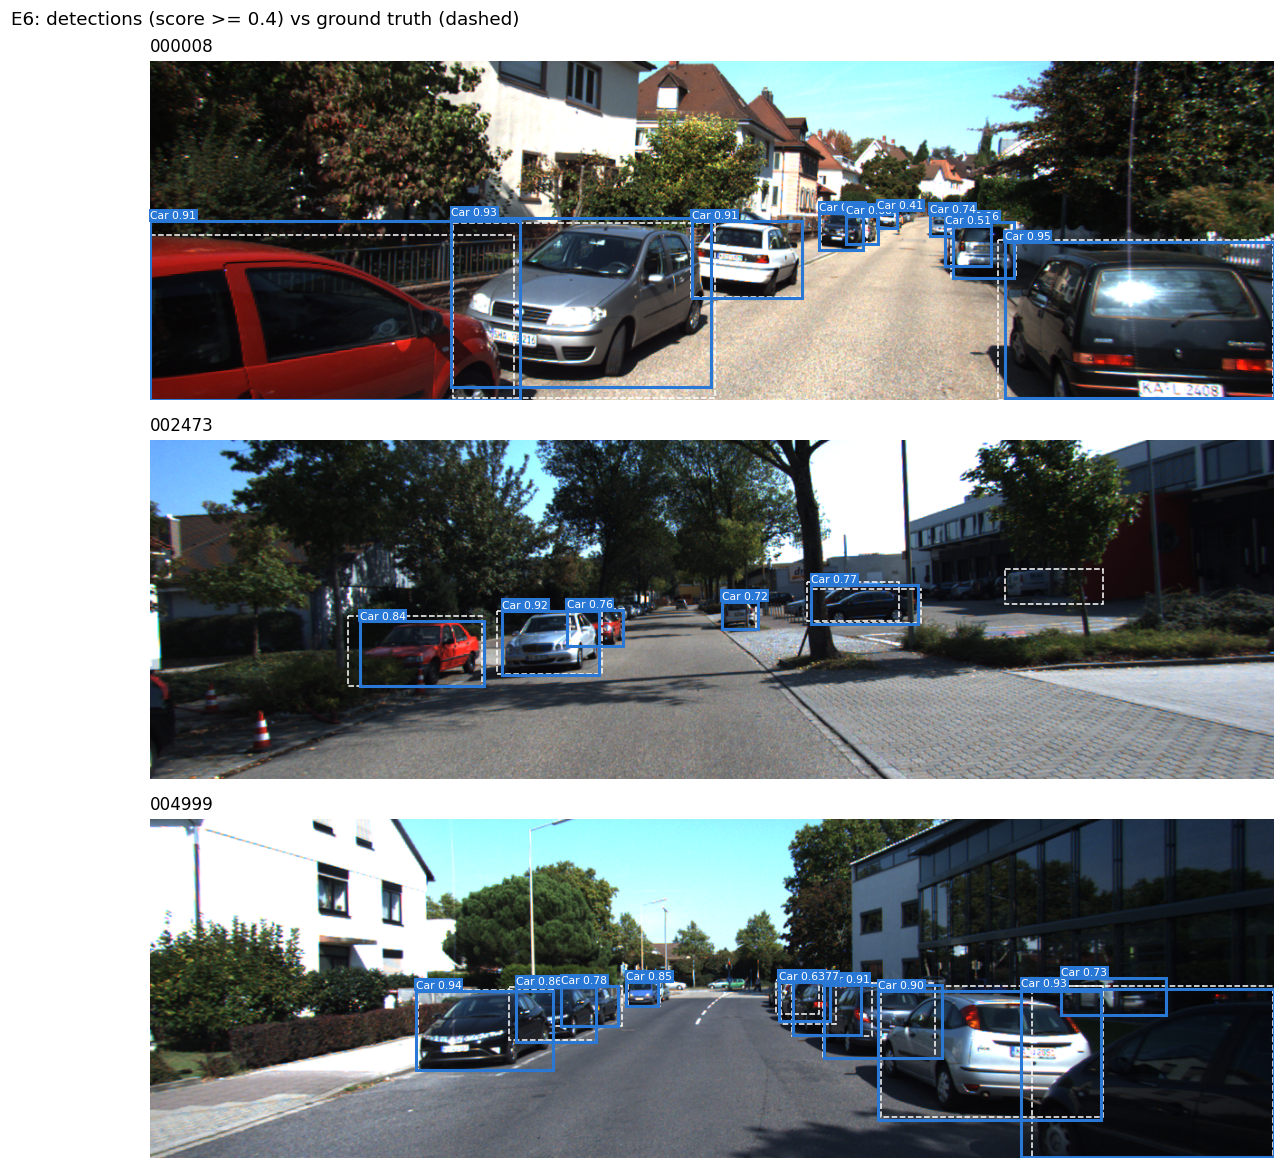

In [11]:
EXAMPLES = split_ids(tables[0], "test")[::max(1, len(split_ids(tables[0], "test")) // 3)][:3]
show_detections("E6", test_preds, tables, EXAMPLES)

## Record

The experiment's row of the experiment log (`results/E6/record.json`).

In [12]:
rec = save_record("E6", "FINAL recipe + weather augmentation (50 % of training images)", "RQ4", val=val, test=test, **info, **{f'test_{k}': v for k, v in ultra.items()})
pd.Series(rec).to_frame("value")

,value
exp_id,E6
description,FINAL recipe + weather augmentation (50 % of t...
research_question,RQ4
model,yolov8s.pt
imgsz,960
batch,16
max_epochs,50
epochs_run,13
best_epoch,3
train_hours,0.639


## E8: the corrupted test sets

Every test image in 3 kinds × 3 severities (9 copies of the test set), seeded per image so both models see exactly
the same images. Severity 1 is light haze / drizzle / dusk, severity 3 dense fog / heavy rain / night.

corrupted test sets:   0%|          | 0/13887 [00:00<?, ?it/s]

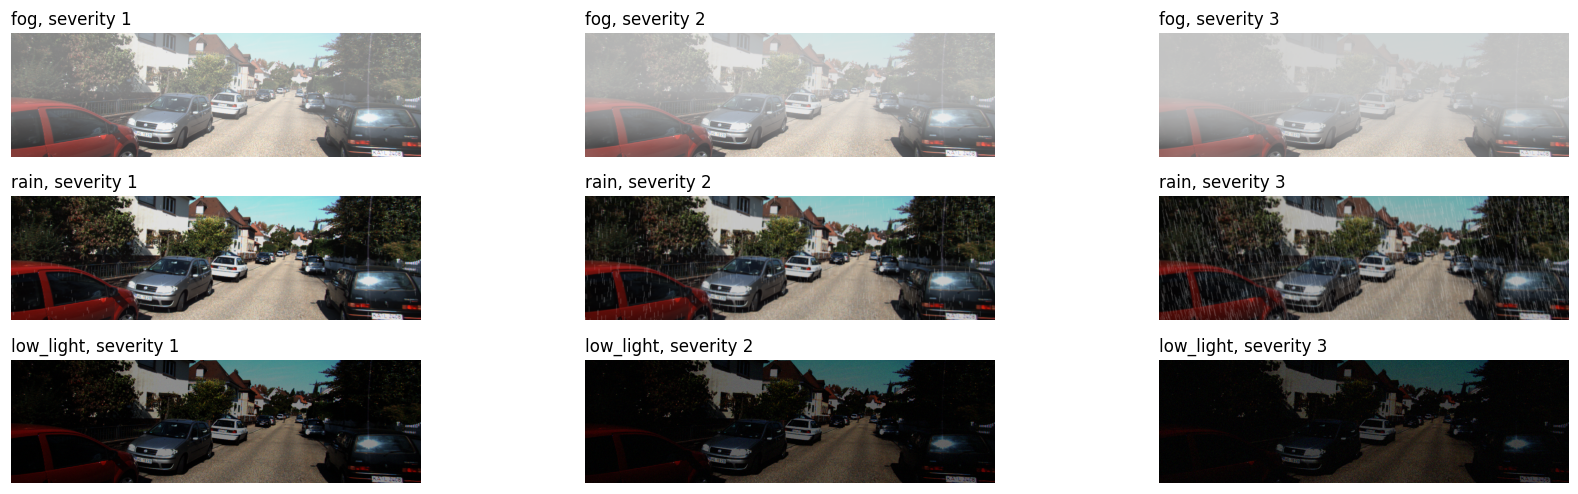

In [13]:
test_ids = split_ids(images, "test")
corr_root = build_corrupted_test(test_ids)
import cv2
fig, ax = plt.subplots(3, 3, figsize=(16, 4.6))
for r, kind in enumerate(WEATHER):
    for c, s in enumerate(SEVERITIES):
        ax[r, c].imshow(cv2.imread(str(corr_root / f"{kind}_s{s}" / f"{test_ids[0]}.png"))[..., ::-1])
        ax[r, c].set_title(f"{kind}, severity {s}", loc="left"); ax[r, c].axis("off"); ax[r, c].grid(False)
plt.tight_layout(); plt.show()

In [14]:
final_rec = load_record("FINAL")
rows = []
for m in ["FINAL", "E6"]:
    clean = final_rec if m == "FINAL" else {f"test_{k}": v for k, v in test.items()}
    rows.append({"model": m, "weather": "clean", "severity": 0, "primary_mAP50_mod": clean["test_primary_mAP50_mod"],
                 **{c: clean[f"test_AP50_{c}_moderate"] for c in FOCUS}})
    for kind, s in tqdm([(k, s) for k in WEATHER for s in SEVERITIES], desc=f"E8: {m} on corrupted test sets"):
        summ, _, _ = evaluate_model(m, "yolo", WEIGHTS / f"{m}.pt", tables, "test", imgsz=IMGSZ,
                                    img_dir=corr_root / f"{kind}_s{s}", tag=f"test_{kind}_s{s}")
        rows.append({"model": m, "weather": kind, "severity": s, "primary_mAP50_mod": summ["primary_mAP50_mod"],
                     **{c: summ[f"AP50_{c}_moderate"] for c in FOCUS}})
rob = pd.DataFrame(rows)
rob.to_csv(exp_dir("E8") / "robustness.csv", index=False)
rob.pivot_table(index=["weather", "severity"], columns="model", values="primary_mAP50_mod").round(3)

E8: FINAL on corrupted test sets:   0%|          | 0/9 [00:00<?, ?it/s]

FINAL on test_fog_s1:   0%|          | 0/97 [00:00<?, ?it/s]

FINAL on test_fog_s2:   0%|          | 0/97 [00:00<?, ?it/s]

FINAL on test_fog_s3:   0%|          | 0/97 [00:00<?, ?it/s]

FINAL on test_rain_s1:   0%|          | 0/97 [00:00<?, ?it/s]

FINAL on test_rain_s2:   0%|          | 0/97 [00:00<?, ?it/s]

... (11 outputs left out)

E6 on test_low_light_s1:   0%|          | 0/97 [00:00<?, ?it/s]

E6 on test_low_light_s2:   0%|          | 0/97 [00:00<?, ?it/s]

E6 on test_low_light_s3:   0%|          | 0/97 [00:00<?, ?it/s]

model                  E6  FINAL
weather   severity              
clean     0         0.804  0.799
fog       1         0.772  0.736
          2         0.699  0.655
          3         0.497  0.437
low_light 1         0.747  0.753
          2         0.563  0.504
          3         0.405  0.226
rain      1         0.784  0.772
          2         0.687  0.652
          3         0.444  0.402

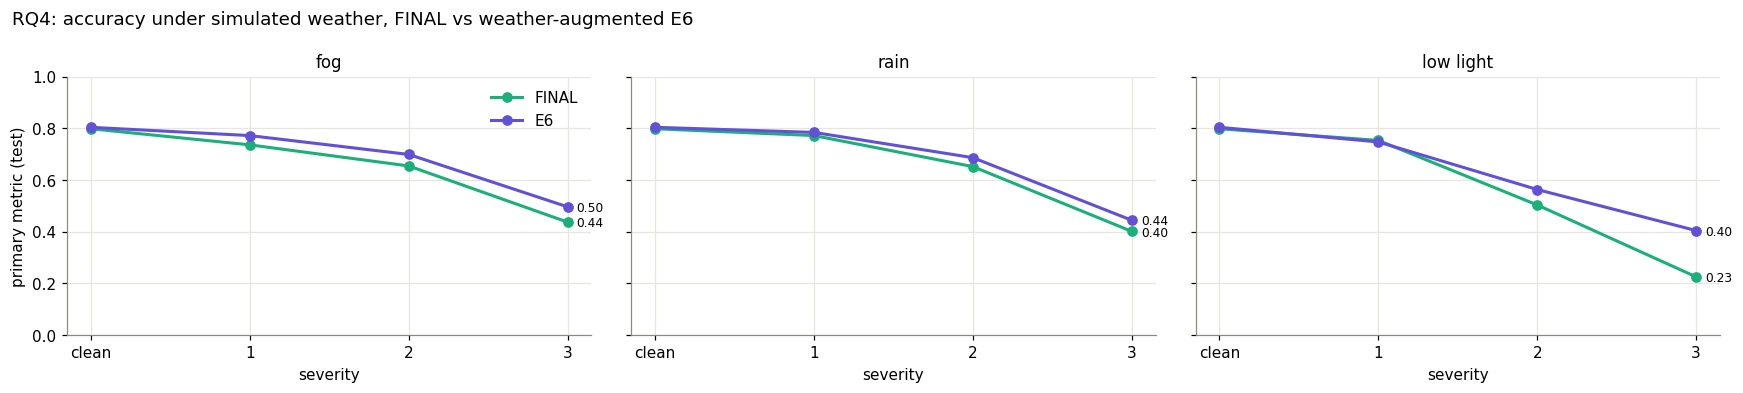

mean over the 9 corrupted sets: FINAL 0.571 | E6 0.622 | difference +0.051


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for a, kind in zip(ax, WEATHER):
    for m in ["FINAL", "E6"]:
        r = rob[(rob.model == m) & rob.weather.isin(["clean", kind])].sort_values("severity")
        a.plot(r.severity, r.primary_mAP50_mod, color=MODEL_C[m], marker="o", ms=6, label=m)
        a.annotate(f"{r.primary_mAP50_mod.iloc[-1]:.2f}", (r.severity.iloc[-1], r.primary_mAP50_mod.iloc[-1]),
                   textcoords="offset points", xytext=(6, -3), fontsize=8)
    a.set_xticks([0, 1, 2, 3], ["clean", "1", "2", "3"]); a.set_xlabel("severity"); a.set_title(kind.replace("_", " "))
ax[0].set_ylabel("primary metric (test)"); ax[0].set_ylim(0, 1); ax[0].legend()
fig.suptitle("RQ4: accuracy under simulated weather, FINAL vs weather-augmented E6", x=0.01, ha="left", fontsize=12)
plt.tight_layout(); fig.savefig(exp_dir("E8") / "figures" / "robustness.png", dpi=130); plt.show()
m = rob[rob.severity > 0].groupby("model").primary_mAP50_mod.mean()
print(f"mean over the 9 corrupted sets: FINAL {m['FINAL']:.3f} | E6 {m['E6']:.3f} | difference {m['E6'] - m['FINAL']:+.3f}")

In [16]:
rec8 = save_record("E8", "FINAL and E6 on fog / rain / low-light test copies, 3 severities", "RQ4",
                   mean_corrupted_FINAL=float(m["FINAL"]), mean_corrupted_E6=float(m["E6"]))

## Observations

- **Weather augmentation costs nothing on clean images:** E6 scores **0.804** on the clean test set against 0.799 for
  FINAL (Pedestrian 0.834 vs 0.797, Cyclist 0.611 vs 0.631).
- **Both models degrade sharply as weather gets worse.** At the strongest severity FINAL drops to 0.44 in fog,
  0.40 in rain and **0.23 in low light**; mild conditions (severity 1) cost only 0.03–0.06.
- **E6 holds up better in every condition at severities 2 and 3.** At severity 3: fog 0.50 vs 0.44, rain 0.44 vs 0.40,
  and **low light 0.40 vs 0.23**, the largest gain. Cars stay detectable for both models; pedestrians and especially
  cyclists collapse (cyclists in heavy rain: 0.03 for FINAL, 0.07 for E6).
- **Limitation:** the weather is simulated with the project's own corruption code and the same family of effects is
  used in training, so this measures robustness to *these* corruptions. Real fog, rain and night images would be
  the honest test, and KITTI does not contain them.